# Trực quan hóa dữ liệu và phân tích

Notebook này trực quan hóa các câu hỏi Q03–Q10 trong `03_analysis_SQL.ipynb` và `04_analysis_python.ipynb`. Nguồn dữ liệu dùng chung là SQLite view `v_review_order_features`, mỗi dòng tương ứng một đơn đã giao có review; cách này tránh đếm lặp theo sản phẩm hoặc thanh toán.

Các biểu đồ tập trung vào phân bố review score và mối liên hệ với giao hàng, phí vận chuyển, giỏ hàng, thanh toán, tháng đặt hàng và bang khách hàng.


In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 130, "axes.titleweight": "bold"})


def find_project_root(start_dir: Path) -> Path:
    for candidate in (start_dir, *start_dir.parents):
        if (
            (candidate / "data" / "olist.db").is_file()
            and (candidate / "Notebooks").is_dir()
            and (candidate / "sql" / "03_queries.sql").is_file()
        ):
            return candidate
    raise FileNotFoundError(
        f"Không tìm thấy thư mục gốc từ {start_dir}. "
        "Hãy chạy scripts/database/build_db.py trước."
    )


BASE_DIR = find_project_root(Path.cwd().resolve())
DB_PATH = BASE_DIR / "data" / "olist.db"
FIG_DIR = BASE_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

with sqlite3.connect(DB_PATH) as conn:
    available_views = {
        row[0]
        for row in conn.execute("SELECT name FROM sqlite_master WHERE type='view'")
    }
    if "v_review_order_features" not in available_views:
        raise RuntimeError(
            "Thiếu view v_review_order_features. "
            "Hãy chạy scripts/database/build_db.py để dựng lại database."
        )
    reviews = pd.read_sql_query(
        "SELECT * FROM v_review_order_features ORDER BY purchase_year_month, order_id",
        conn,
    )

reviews["is_late"] = reviews["is_late"].astype(bool)
reviews["low_score"] = reviews["review_score"] <= 2
reviews["positive_review"] = reviews["review_score"] >= 4
reviews["purchase_year_month"] = pd.to_datetime(
    reviews["purchase_year_month"], format="%Y-%m"
)

def save_figure(fig, filename):
    path = FIG_DIR / filename
    fig.savefig(path, bbox_inches="tight", dpi=180)
    plt.show()
    plt.close(fig)

print(f"Database: {DB_PATH}")
print(f"Đơn hàng có review: {len(reviews):,}")



Database: D:\FPT UNIVERSITY\Kì 3\ADY201m\ADY291c-AI2107-Group2\data\olist.db
Đơn hàng có review: 95,329


## Câu 1 — Phân bố review score

Cùng truy vấn Q03: số lượng và tỷ trọng đơn ở từng mức 1–5 sao. Tỷ trọng giúp nhìn rõ mức độ mất cân bằng của nhãn review.


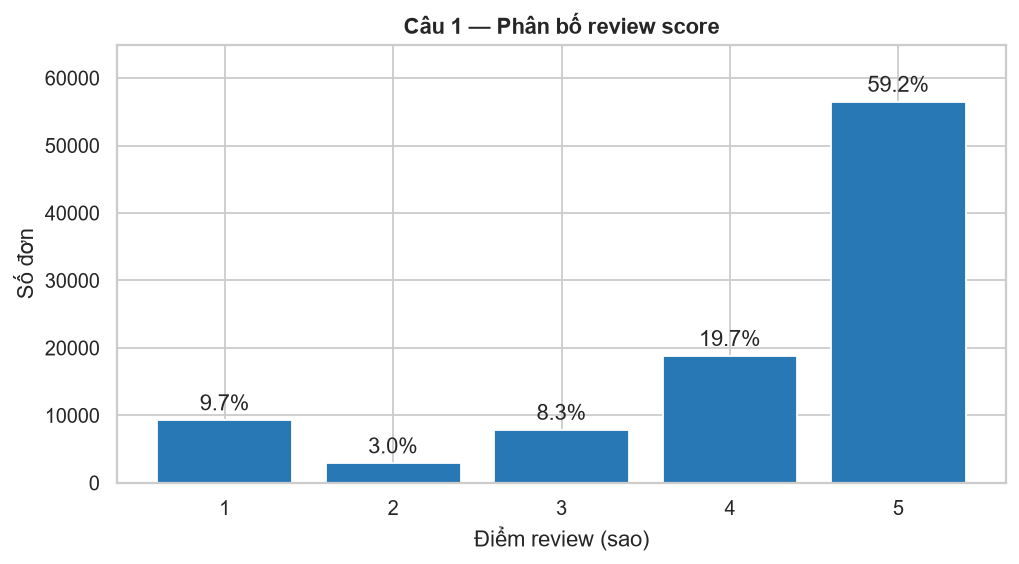

In [2]:
q03 = reviews.groupby("review_score").size().reindex(range(1, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(q03.index.astype(str), q03.values, color="#2878B5")
ax.bar_label(bars, labels=[f"{v / q03.sum():.1%}" for v in q03.values], padding=3)
ax.set(title="Câu 1 — Phân bố review score", xlabel="Điểm review (sao)", ylabel="Số đơn")
ax.margins(y=0.15)
fig.tight_layout()
save_figure(fig, "05_01_review_score_distribution.png")


**Nhận xét:** Điểm trung bình chung là **4,16/5**; 5 sao chiếm **59,25%** (56.480 đơn), trong khi review 1–2 sao chiếm **12,77%**. Phân bố nghiêng về điểm cao, do đó tỷ lệ từng mức cũng cần được xem xét thay vì chỉ dựa vào điểm trung bình.


## Câu 2 — Giao trễ và giao đúng hạn so với review

So sánh điểm trung bình, tỷ lệ review tích cực (≥4 sao) và review thấp (≤2 sao) giữa hai nhóm giao hàng, thống nhất với Q04 SQL.


                   order_count  avg_review_score  positive_pct  low_score_pct
is_late                                                                      
Đúng hạn hoặc sớm        88978              4.29         82.71           9.23
Giao trễ                  6351              2.27         26.72          62.37


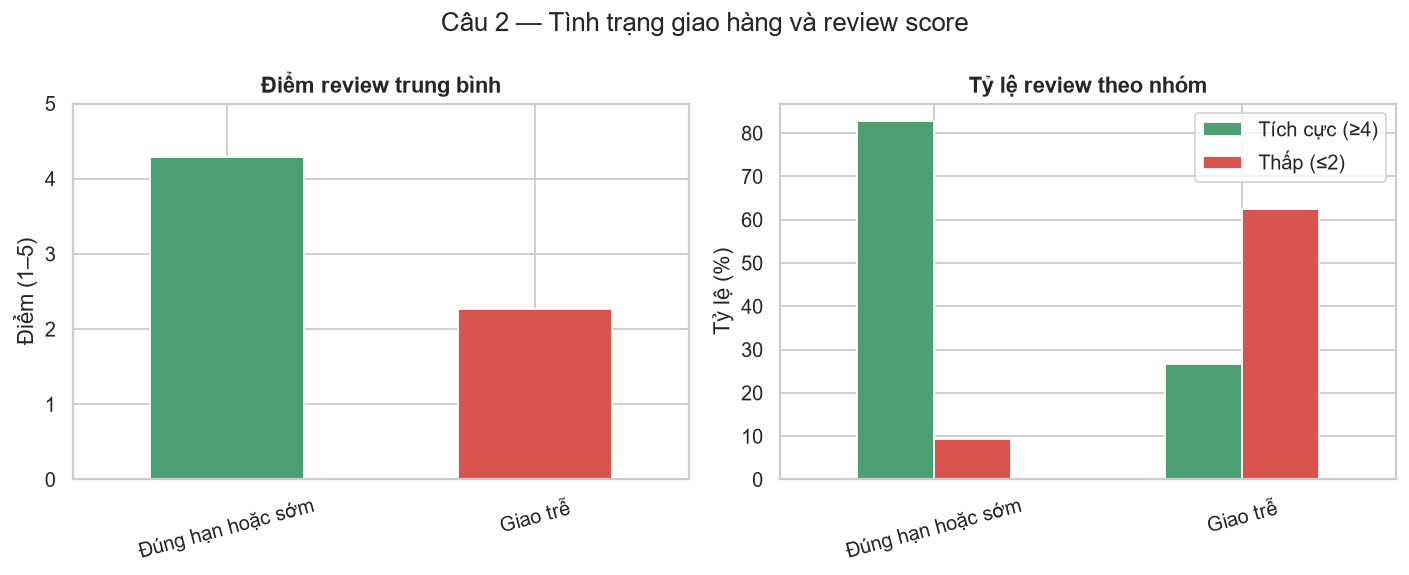

In [3]:
q04 = reviews.groupby("is_late").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
    low_score_pct=("low_score", "mean"),
).rename(index={False: "Đúng hạn hoặc sớm", True: "Giao trễ"})
q04[["positive_pct", "low_score_pct"]] *= 100
print(q04.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
q04["avg_review_score"].plot(kind="bar", ax=axes[0], color=["#4C9F70", "#D9534F"])
axes[0].set(title="Điểm review trung bình", ylabel="Điểm (1–5)", xlabel="")
axes[0].set_ylim(0, 5)
axes[0].tick_params(axis="x", rotation=15)
q04[["positive_pct", "low_score_pct"]].plot(kind="bar", ax=axes[1], color=["#4C9F70", "#D9534F"])
axes[1].set(title="Tỷ lệ review theo nhóm", ylabel="Tỷ lệ (%)", xlabel="")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(["Tích cực (≥4)", "Thấp (≤2)"])
fig.suptitle("Câu 2 — Tình trạng giao hàng và review score")
fig.tight_layout()
save_figure(fig, "05_02_late_vs_review_score.png")


**Nhận xét:** Nhóm giao trễ có điểm trung bình **2,27**, thấp hơn nhóm đúng hạn/sớm (**4,29**); tỷ lệ review thấp là **62,37%** so với **9,23%**. Ngược lại, tỷ lệ review tích cực ở nhóm đúng hạn là **82,71%**, cao hơn nhiều so với **26,72%** ở nhóm trễ. Đây là mối liên hệ rõ trong dữ liệu, không khẳng định giao trễ là nguyên nhân duy nhất.


## Câu 3 — Mức độ trễ theo ngày và review score

Dùng đúng các nhóm trễ trong Q05 SQL: sớm/đúng hạn, trễ 1–3 ngày, 4–7 ngày và trên 7 ngày.


                   order_count  avg_review_score  positive_pct
delay_group                                                   
Sớm hoặc đúng hạn        88978              4.29         82.71
Trễ 1–3 ngày              1841              3.29         53.23
Trễ 4–7 ngày              1741              2.11         22.57
Trễ trên 7 ngày           2769              1.69         11.70


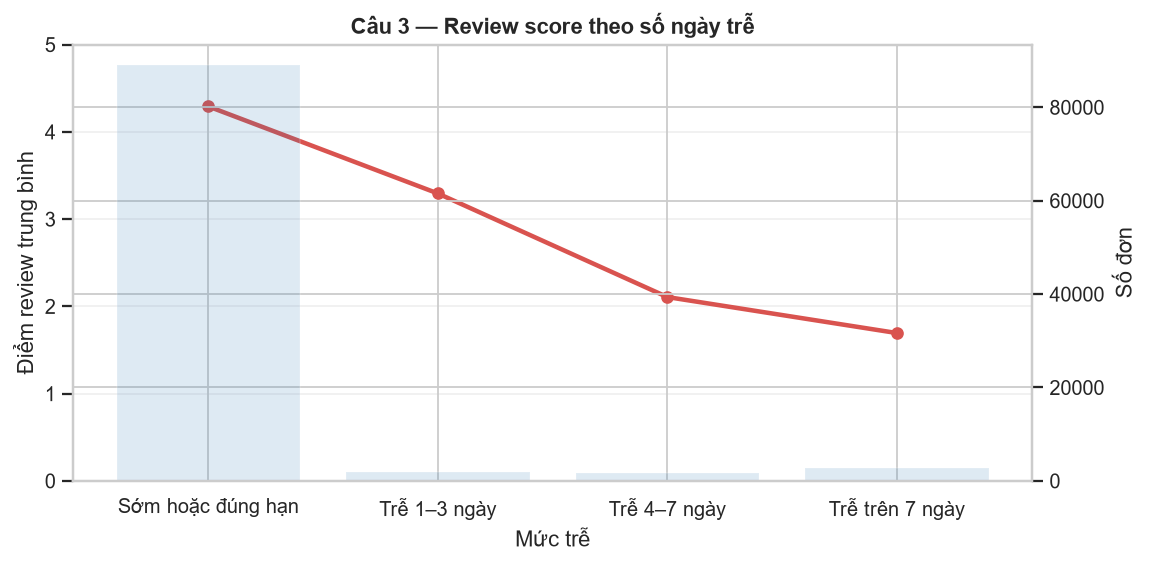

In [4]:
delay_labels = ["Sớm hoặc đúng hạn", "Trễ 1–3 ngày", "Trễ 4–7 ngày", "Trễ trên 7 ngày"]
reviews["delay_group"] = pd.cut(
    reviews["delay_days"], [-np.inf, 0, 3, 7, np.inf], labels=delay_labels
)
q05 = reviews.groupby("delay_group", observed=False).agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    positive_pct=("positive_review", "mean"),
)
q05["positive_pct"] *= 100
print(q05.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(q05.index.astype(str), q05["avg_review_score"], marker="o", linewidth=2.5, color="#D9534F")
ax.set(title="Câu 3 — Review score theo số ngày trễ", xlabel="Mức trễ", ylabel="Điểm review trung bình")
ax.set_ylim(0, 5)
ax.grid(axis="y", alpha=0.3)
ax2 = ax.twinx()
ax2.bar(q05.index.astype(str), q05["order_count"], alpha=0.15, color="#2878B5")
ax2.set_ylabel("Số đơn")
fig.tight_layout()
save_figure(fig, "05_03_delay_vs_review_score.png")


**Nhận xét:** Điểm trung bình giảm theo mức trễ: **3,29** ở nhóm trễ 1–3 ngày, **2,11** ở nhóm 4–7 ngày và **1,69** ở nhóm trễ trên 7 ngày. Số đơn trễ trên 7 ngày là **2.769**, trong đó chỉ **11,70%** review tích cực; biểu đồ cho thấy mức giảm điểm diễn ra cùng lúc số ngày trễ tăng.


## Câu 4 — Phí vận chuyển và tỷ lệ phí/giá hàng

Chia đơn thành bốn quartile theo tổng phí ship và theo tỷ lệ phí ship/giá trị hàng như Q06 SQL. So sánh điểm review trung bình, đồng thời hiển thị cỡ mẫu.


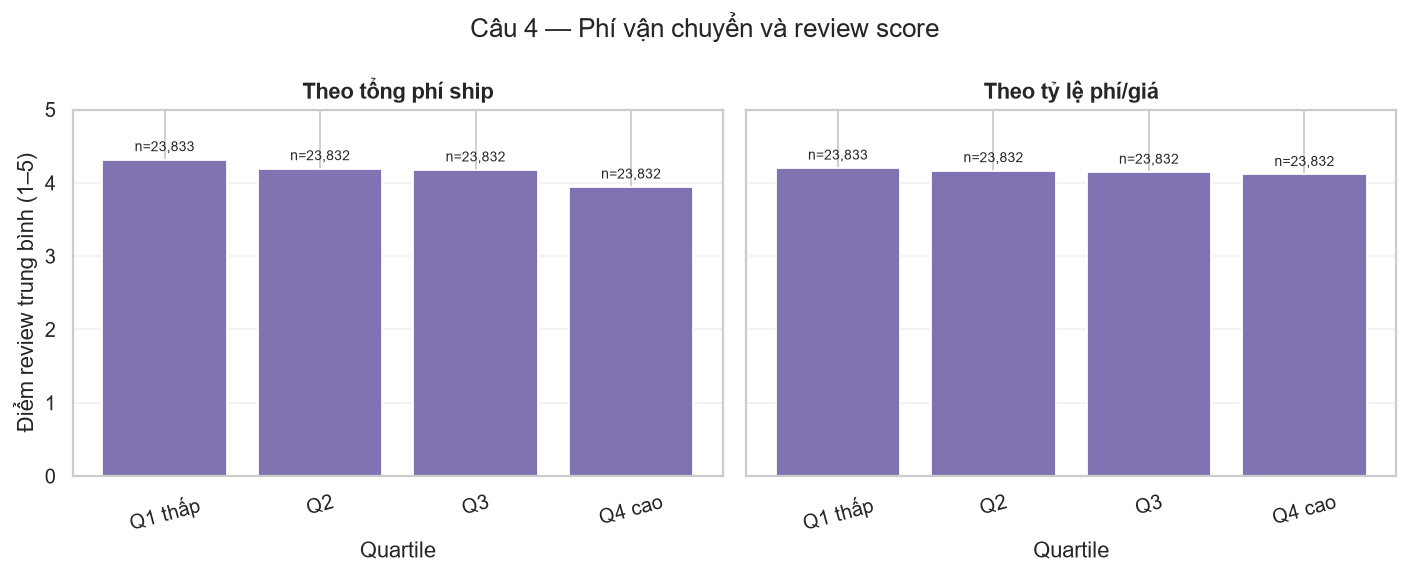

In [5]:
quartiles = ["Q1 thấp", "Q2", "Q3", "Q4 cao"]
reviews["freight_quartile"] = pd.qcut(reviews["total_freight"].rank(method="first"), 4, labels=quartiles)
valid_ratio = reviews.dropna(subset=["freight_to_price_pct"]).copy()
valid_ratio["ratio_quartile"] = pd.qcut(
    valid_ratio["freight_to_price_pct"].rank(method="first"), 4, labels=quartiles
)
q06_freight = reviews.groupby("freight_quartile", observed=False).agg(
    order_count=("order_id", "size"), avg_review_score=("review_score", "mean")
)
q06_ratio = valid_ratio.groupby("ratio_quartile", observed=False).agg(
    order_count=("order_id", "size"), avg_review_score=("review_score", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, summary, title in [
    (axes[0], q06_freight, "Theo tổng phí ship"),
    (axes[1], q06_ratio, "Theo tỷ lệ phí/giá"),
]:
    bars = ax.bar(summary.index.astype(str), summary["avg_review_score"], color="#8172B2")
    ax.bar_label(bars, labels=[f"n={n:,}" for n in summary["order_count"]], padding=3, fontsize=8)
    ax.set(title=title, xlabel="Quartile", ylim=(0, 5))
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Điểm review trung bình (1–5)")
fig.suptitle("Câu 4 — Phí vận chuyển và review score")
fig.tight_layout()
save_figure(fig, "05_04_freight_vs_review_score.png")


**Nhận xét:** Điểm trung bình giảm từ **4,32** ở quartile phí ship thấp xuống **3,94** ở quartile cao; trong khi theo tỷ lệ phí/giá mức chênh nhỏ hơn (**4,20** so với **4,11**). Vì mỗi nhóm có khoảng **23.832–23.833 đơn**, chênh lệch không chỉ đến từ vài quan sát đơn lẻ; tuy vậy biểu đồ này mô tả mối liên hệ, không chứng minh phí vận chuyển gây ra đánh giá thấp.


## Câu 5 — Độ phức tạp đơn hàng

So sánh điểm review và tỷ lệ review thấp theo số mặt hàng trong giỏ và số người bán trong đơn, theo nhóm trong Q07 SQL.


                              order_count  avg_review_score  low_score_pct
basket_group seller_group                                                 
1 mặt hàng   1 người bán            85857              4.21          11.24
2–3 mặt hàng 1 người bán             7417              3.78          22.83
             Nhiều người bán         1134              2.90          46.12
4+ mặt hàng  1 người bán              807              3.49          30.48
             Nhiều người bán          114              2.49          59.65


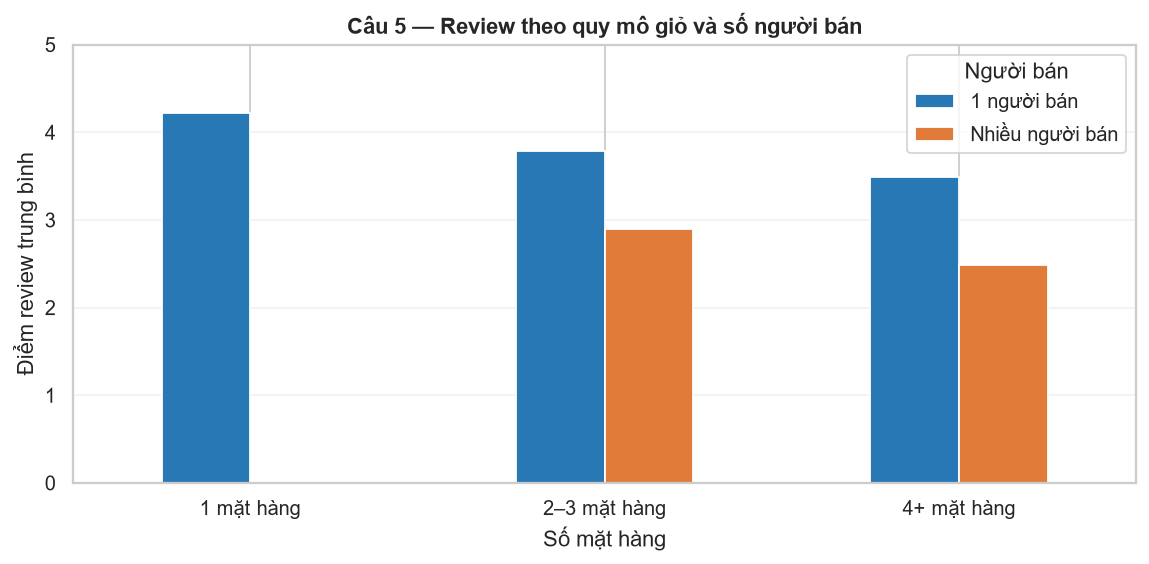

In [6]:
reviews["basket_group"] = np.select(
    [reviews["item_count"].eq(1), reviews["item_count"].between(2, 3)],
    ["1 mặt hàng", "2–3 mặt hàng"], default="4+ mặt hàng"
)
reviews["seller_group"] = np.where(reviews["seller_count"].eq(1), "1 người bán", "Nhiều người bán")
q07 = reviews.groupby(["basket_group", "seller_group"]).agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
)
q07["low_score_pct"] *= 100
print(q07.round(2))

score = q07["avg_review_score"].unstack("seller_group")
fig, ax = plt.subplots(figsize=(9, 4.5))
score.plot(kind="bar", ax=ax, color=["#2878B5", "#E07B39"])
ax.set(title="Câu 5 — Review theo quy mô giỏ và số người bán", xlabel="Số mặt hàng", ylabel="Điểm review trung bình")
ax.set_ylim(0, 5)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Người bán")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, "05_05_order_complexity_vs_review_score.png")


**Nhận xét:** Điểm giảm khi giỏ hàng lớn hơn và có nhiều người bán: đơn một mặt hàng/một người bán đạt **4,21**, còn nhóm 4+ mặt hàng/nhiều người bán đạt **2,49**; tỷ lệ review thấp ở nhóm sau là **59,65%**. Tuy nhiên, nhóm này chỉ có **114 đơn**, nên cần thận trọng khi khái quát kết quả.


## Câu 6 — Phương thức thanh toán và trả góp

Đối chiếu điểm trung bình, tỷ lệ review thấp và cỡ mẫu theo `first_payment_type`, như Q08 SQL.


                    order_count  avg_installments  avg_review_score  \
first_payment_type                                                    
credit_card               73385               3.5              4.16   
boleto                    18970               1.0              4.16   
voucher                    1473               1.0              4.11   
debit_card                 1424               1.0              4.25   

                    low_score_pct  
first_payment_type                 
credit_card                 12.84  
boleto                      12.51  
voucher                     14.32  
debit_card                  10.88  


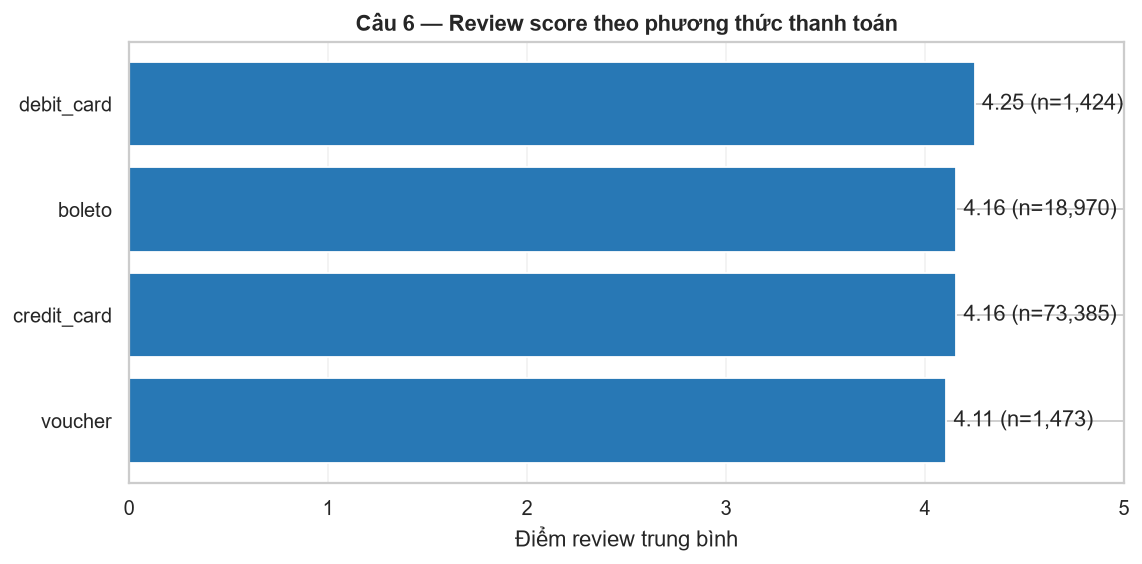

In [7]:
q08 = reviews.dropna(subset=["first_payment_type"]).groupby("first_payment_type").agg(
    order_count=("order_id", "size"),
    avg_installments=("max_installments", "mean"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
).sort_values("order_count", ascending=False)
q08["low_score_pct"] *= 100
print(q08.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = q08.sort_values("avg_review_score")
bars = ax.barh(plot_data.index, plot_data["avg_review_score"], color="#2878B5")
ax.bar_label(bars, labels=[f"{score:.2f} (n={n:,})" for score, n in zip(plot_data["avg_review_score"], plot_data["order_count"])], padding=4)
ax.set(title="Câu 6 — Review score theo phương thức thanh toán", xlabel="Điểm review trung bình", xlim=(0, 5))
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
save_figure(fig, "05_06_payment_vs_review_score.png")


**Nhận xét:** Các phương thức phổ biến có điểm trung bình khá gần nhau: credit card và boleto đều **4,16**, voucher **4,11**; debit card đạt **4,25** trên **1.424 đơn**. Nhóm debit card có tỷ lệ review thấp **10,88%**, thấp hơn credit card (**12,84%**), nhưng khác biệt quan sát được không đủ để kết luận phương thức thanh toán làm thay đổi mức hài lòng.


## Câu 7 — Xu hướng review theo tháng đặt hàng

Thể hiện điểm review trung bình, tỷ lệ review thấp và số đơn theo tháng đặt hàng, tương ứng với Q09 SQL. Tháng đặt hàng là mốc nhất quán trong view; không diễn giải nó thành tháng review được gửi.


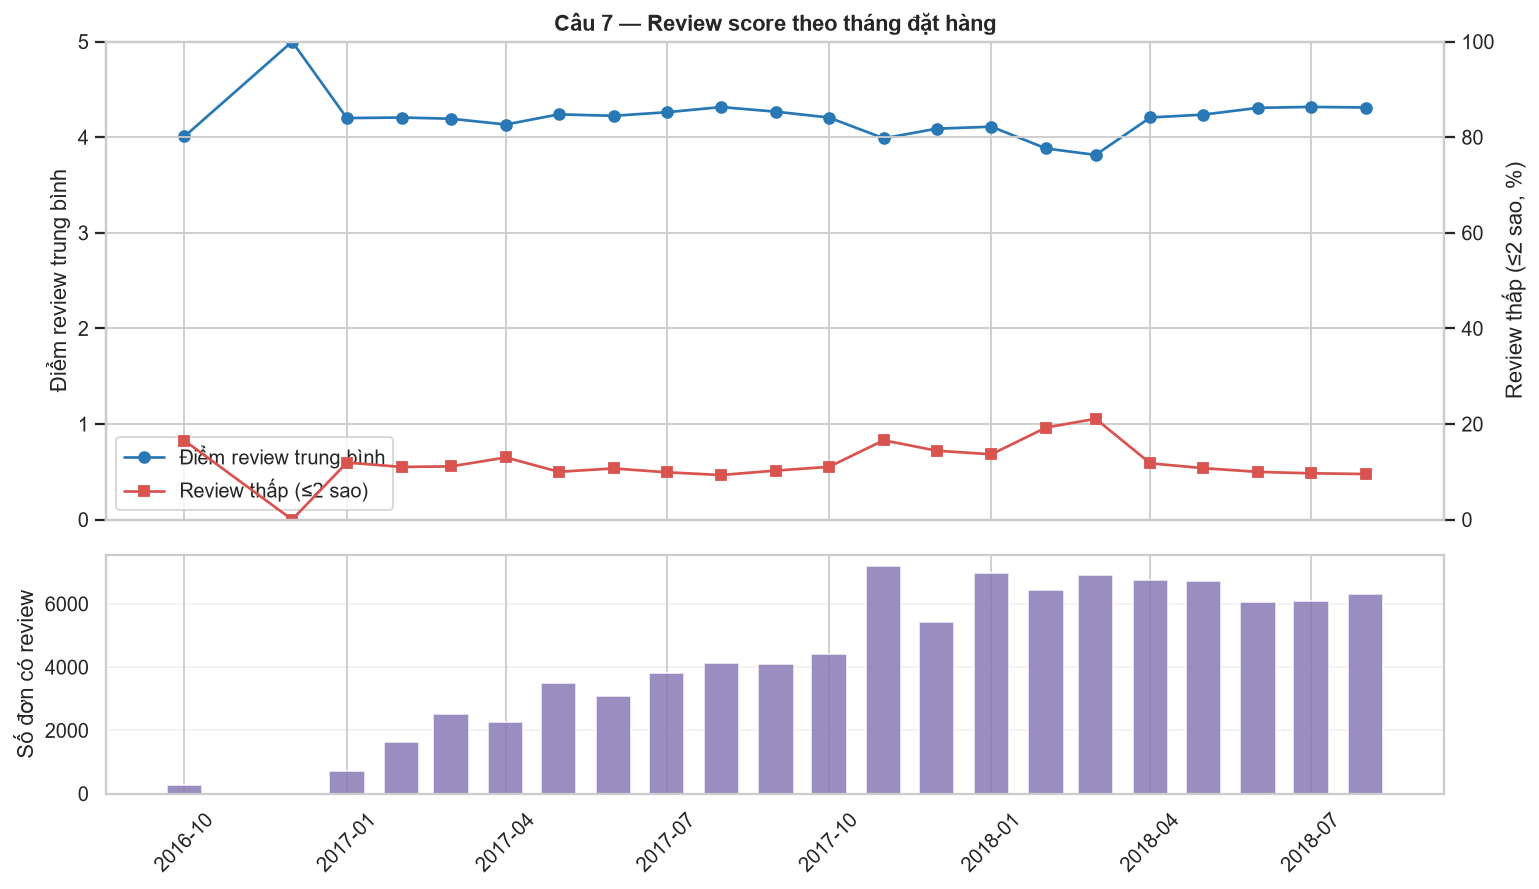

In [8]:
q09 = reviews.groupby("purchase_year_month").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
).sort_index()
q09["low_score_pct"] *= 100

fig, (ax_score, ax_count) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
ax_score.plot(q09.index, q09["avg_review_score"], marker="o", color="#2878B5", label="Điểm review trung bình")
ax_score.set(title="Câu 7 — Review score theo tháng đặt hàng", ylabel="Điểm review trung bình", ylim=(0, 5))
ax_score.grid(axis="y", alpha=0.25)
ax_rate = ax_score.twinx()
ax_rate.plot(q09.index, q09["low_score_pct"], marker="s", color="#D9534F", label="Review thấp (≤2 sao)")
ax_rate.set_ylabel("Review thấp (≤2 sao, %)")
ax_rate.set_ylim(0, 100)
lines = ax_score.get_lines() + ax_rate.get_lines()
ax_score.legend(lines, [line.get_label() for line in lines], loc="best")
ax_count.bar(q09.index, q09["order_count"], width=20, color="#8172B2", alpha=0.8)
ax_count.set_ylabel("Số đơn có review")
ax_count.grid(axis="y", alpha=0.25)
ax_count.tick_params(axis="x", rotation=45)
fig.tight_layout()
save_figure(fig, "05_07_monthly_review_score.png")

**Nhận xét:** Điểm theo tháng dao động thay vì tăng đều: từ **4,32** vào 08/2017 giảm xuống **3,81** vào 03/2018, rồi phục hồi lên **4,31** vào 06/2018. Tỷ lệ review thấp cũng tăng lên **21,09%** vào 03/2018 trước khi giảm về khoảng **9,5–10,0%** vào 06–08/2018. Các tháng đầu có ít quan sát hơn; xu hướng không nên diễn giải thành quan hệ nhân quả.


## Câu 8 — Mức hài lòng theo bang khách hàng

Quan sát điểm review, tỷ lệ giao trễ và tỷ lệ review thấp theo bang (chỉ giữ bang có ít nhất 100 đơn, như Q10 SQL). Kích thước điểm biểu thị số đơn; biểu đồ cho thấy liên hệ địa lý, không phải quan hệ nhân quả.


                order_count  avg_review_score  low_score_pct  late_rate_pct
customer_state                                                             
MA                      706              3.82          20.11          17.28
AL                      393              3.85          21.12          20.61
SE                      332              3.90          18.98          15.06
PA                      924              3.92          17.86          10.82
BA                     3213              3.93          16.99          11.89
CE                     1272              3.94          17.14          13.68
RJ                    12136              3.97          18.27          11.95
PI                      470              3.99          16.17          13.62
PB                      510              4.07          14.90          10.20
ES                     1963              4.08          13.81          10.44
PE                     1573              4.08          14.88           9.47
GO          

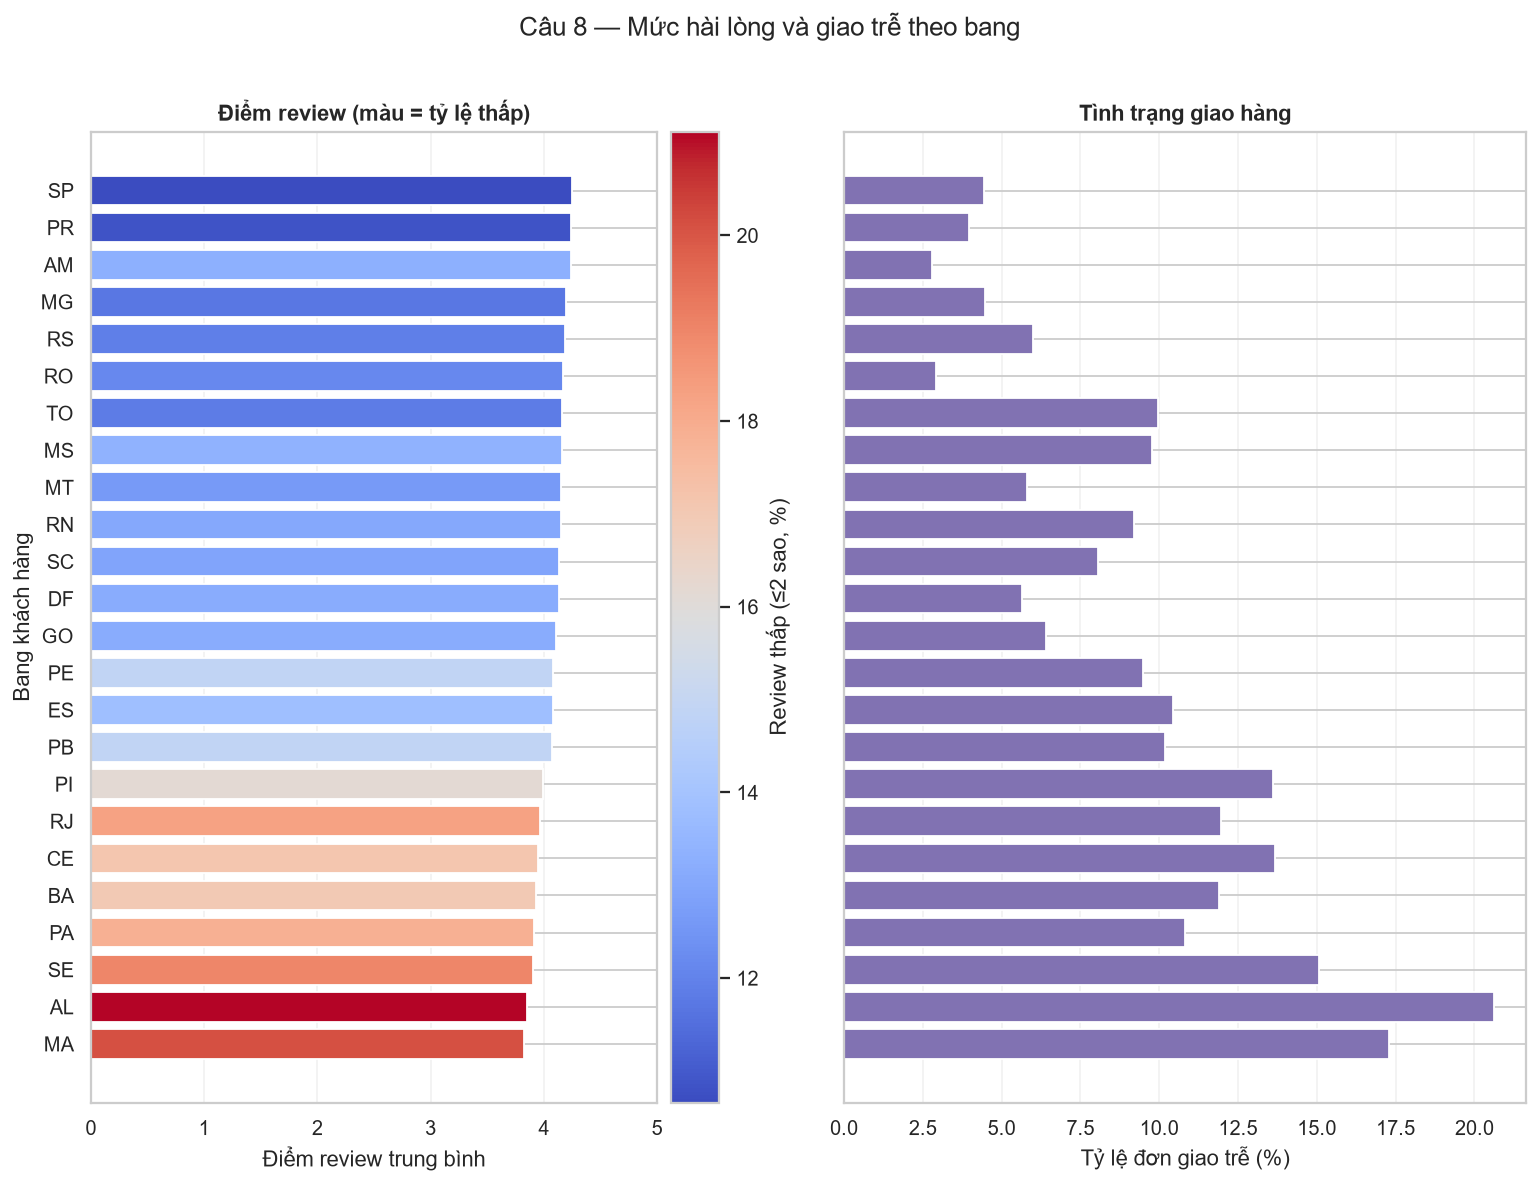

In [9]:
q10 = reviews.groupby("customer_state").agg(
    order_count=("order_id", "size"),
    avg_review_score=("review_score", "mean"),
    low_score_pct=("low_score", "mean"),
    late_rate_pct=("is_late", "mean"),
)
q10 = q10.loc[q10["order_count"] >= 100].sort_values("avg_review_score")
q10[["low_score_pct", "late_rate_pct"]] *= 100
print(q10.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharey=True)
colors = plt.cm.coolwarm(plt.Normalize(q10["low_score_pct"].min(), q10["low_score_pct"].max())(q10["low_score_pct"]))
axes[0].barh(q10.index, q10["avg_review_score"], color=colors)
axes[0].set(title="Điểm review (màu = tỷ lệ thấp)", xlabel="Điểm review trung bình", xlim=(0, 5))
axes[0].set_ylabel("Bang khách hàng")
axes[0].grid(axis="x", alpha=0.25)
axes[1].barh(q10.index, q10["late_rate_pct"], color="#8172B2")
axes[1].set(title="Tình trạng giao hàng", xlabel="Tỷ lệ đơn giao trễ (%)")
axes[1].grid(axis="x", alpha=0.25)
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(q10["low_score_pct"].min(), q10["low_score_pct"].max()), cmap="coolwarm"), ax=axes[0], pad=0.02)
colorbar.set_label("Review thấp (≤2 sao, %)")
fig.suptitle("Câu 8 — Mức hài lòng và giao trễ theo bang", y=1.01)
fig.tight_layout()
save_figure(fig, "05_08_review_by_state.png")

**Nhận xét:** Trong các bang có ít nhất 100 đơn, MA có điểm thấp nhất (**3,82**, 706 đơn) và tỷ lệ giao trễ **17,28%**; SP có điểm cao nhất (**4,25**, 40.063 đơn) với tỷ lệ trễ **4,44%**. Mẫu của các bang rất khác nhau, nên cần kết hợp cỡ mẫu khi so sánh; tương quan địa lý không khẳng định quan hệ nhân quả.


## Tổng kết

Tám biểu đồ tóm lược phân bố review score và các mối liên hệ quan sát được trong dữ liệu. Nổi bật nhất là khác biệt về điểm đánh giá giữa đơn giao trễ và đúng hạn; các nhóm phí vận chuyển, giỏ hàng, thanh toán, thời điểm và bang cũng cho thấy các mức chênh lệch khác nhau. Đây là các kết quả mô tả, không khẳng định quan hệ nhân quả.
